## Przegląd bibliotek ML i budowa pipeline'u treningowego
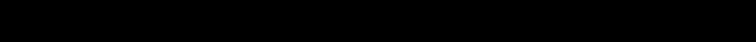
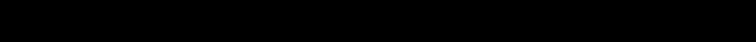
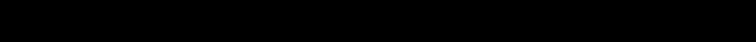

In [19]:
# import odpowiednich bibliotek
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import time

In [20]:
# wczytanie zbiorów danych
data = load_wine(as_frame=True)
wine_data = data.data
wine_targets = data.target

### Testowanie biblioteki Scikit-learn na wybranym zbiorze

In [21]:
# podział danych na trening/test
TEST_SIZE = 0.2
RANDOM_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(wine_data, wine_targets, test_size=TEST_SIZE, random_state=RANDOM_SEED)

# stworzenie pipeline'u
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])

In [22]:
# definiowanie tablic dla porownania
timestamps = []
accuracies = []
f1_scores = []

# trenowanie modelu
start_time = time.time()
pipeline.fit(X_train, y_train)
end_time = time.time() - start_time
timestamps.append(end_time)

# notowanie wyników
y_pred = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
accuracies.append(accuracy)
f1_score = f1_score(y_test, y_pred, average='micro')
f1_scores.append(f1_score)
classification_report = classification_report(y_test, y_pred)

# wyświetlenie rezultatu treningu
print("Accuracy: ", accuracy)
print("F1 Score: ", f1_score)
print(classification_report)

Accuracy:  1.0
F1 Score:  1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



### Tworzenie sieci neuronowej

In [23]:
# sprawdzenie wymiarów danych
print("Wymiary danych zapisanych: ", wine_data.shape)

Wymiary danych zapisanych:  (178, 13)


In [29]:
# wczytanie zbiorów danych
data = load_wine()
X = data.data
y = data.target

# standaryzacja cech i konwersja do tensorów
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# stworzenie tensorów
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print("Wymiary danych: ", X_train.shape)
print("Wymiar etykiet: ", y_train.shape)

Wymiary danych:  torch.Size([142, 13])
Wymiar etykiet:  torch.Size([142])
